# Introduction
This notebook will perform extensive data analysis regarding bird bioacoustic monitoring. The data will be taken from the article "Automated identification of individual birds by song enables multi-year recapture from passive acoustic monitoring data", and it is located under resources/localized_events.csv. 

## Package Imports

In [1]:
# First, we must import the necessary packages and libraries
import pandas as pd
from pandas import DataFrame
import ast
import math
from pathlib import Path 
import matplotlib.pyplot as plt
import networkx as nx
from pyvis.network import Network
from plotnine import ( 
    ggplot, 
    aes, 
    geom_point,
    geom_bar,
    facet_wrap,
    labs,
    scale_fill_manual,
    theme_minimal
)

## Data Loading

Then, we will need to load in the data as a dataframe or just fetch the binary if it exists

In [2]:
path = Path("resources/localized_events.parquet")

if path.exists():
    print("Exists, so just load in binary file")
    all_loaded_events_df = pd.read_parquet("resources/localized_events.parquet")
else:
    print("Does not exist, so we create it")
    all_loaded_events_df = pd.read_csv("resources/localized_events.csv")
    all_loaded_events_df.to_parquet("resources/localized_events.parquet")


Exists, so just load in binary file


## Configurations

Include the user configurations here for easy access

### Time Filters

In [3]:
# Bounds for Event Overlap
LOWER = 5
UPPER = 5

# Time Range Setup
START_OFF = 20 # 20 minutes after the first acoustic event
DURATION = 30 # range will be for 10 minutes

### Distance Filter

In [4]:
# Specify the distance in meters for Spacial Overlap
EUCLIDEAN_DIST = 100

## Data Preparation

Now, we will take a subset of the column variables in the data spreadsheet.

#### Subset Data Frame

In [5]:
subst_loaded_events_df = all_loaded_events_df[
    [
    # Metadata
    'array',
    'data_split',
    'relative_position',
    'mic_distances_m',
    'start_timestamp',
    'duration',

    # Automated models
    'ovenbird_cluster_labels',
    'baseline_resnet18_cluster_labels',
    'hawkears_cluster_labels',
    'birdnet_cluster_labels',
    ]
]

In [6]:
# add a new column individual so it does not conflict with python
subst_loaded_events_df['individual'] = all_loaded_events_df['class']

# Convert to datetime objects
subst_loaded_events_df['start_timestamp'] = pd.to_datetime(subst_loaded_events_df['start_timestamp'], utc=True)
subst_loaded_events_df['duration'] = pd.to_timedelta(subst_loaded_events_df['duration'], unit='minute')

In [7]:
# Create a new column just for the end_timestamp -> datetime object
subst_loaded_events_df['end_timestamp'] = (subst_loaded_events_df['start_timestamp'] + subst_loaded_events_df['duration'])

In [8]:
# Set an event key for all the rows
subst_loaded_events_df['event_key'] = range(len(subst_loaded_events_df))

In [9]:
# .value_counts() creates a lookup table, (individual: counts) for all individuals
# .map() takes that lookup table and assigns it to those individuals using 'individual' as the key
# This new column 'count' is assigned with that counts for each individual
lookup_individual_counts = subst_loaded_events_df['individual'].value_counts()
subst_loaded_events_df['count'] = subst_loaded_events_df['individual'].map(
    lookup_individual_counts
)

In [10]:
# Save to under resources
subst_loaded_events_df.to_parquet('resources/subset_loaded_events.parquet')
subst_loaded_events_df.to_csv('resources/subset_loaded_events.csv')

#### Metrics Dataframe Construction

Only keep the critical columns within the subset dataframe to cut down on unneeded memory usage

In [11]:
cols = subst_loaded_events_df.columns
metrics_df = subst_loaded_events_df[['event_key', 'individual', 'start_timestamp', 'end_timestamp', 'relative_position']]

metrics_df['relative_position'] = metrics_df['relative_position'].apply(
                                    ast.literal_eval
                                  )

metrics_df['position_x'] = metrics_df['relative_position'].apply(
    lambda p: p[0]
)

metrics_df['position_y'] = metrics_df['relative_position'].apply(
    lambda p: p[1]
)

metrics_df['site'] = subst_loaded_events_df['array']

In [12]:
# create a new column that scales the start and end
metrics_df['scale_time_start'] = metrics_df['start_timestamp'] - pd.to_timedelta(LOWER, unit='minute')
metrics_df['scale_time_end'] = metrics_df['end_timestamp'] + pd.to_timedelta(UPPER, unit='minute')

# drop the original start and end time_stamps
metrics_df = metrics_df.drop(columns=['start_timestamp', 'end_timestamp', 'relative_position'])

# set the event_key as the index
metrics_df = metrics_df.set_index("event_key")

## Exploratory Data Analysis
We will begin by exploring the distributions of the data to identify possible outliers, trends, and occurrences. 

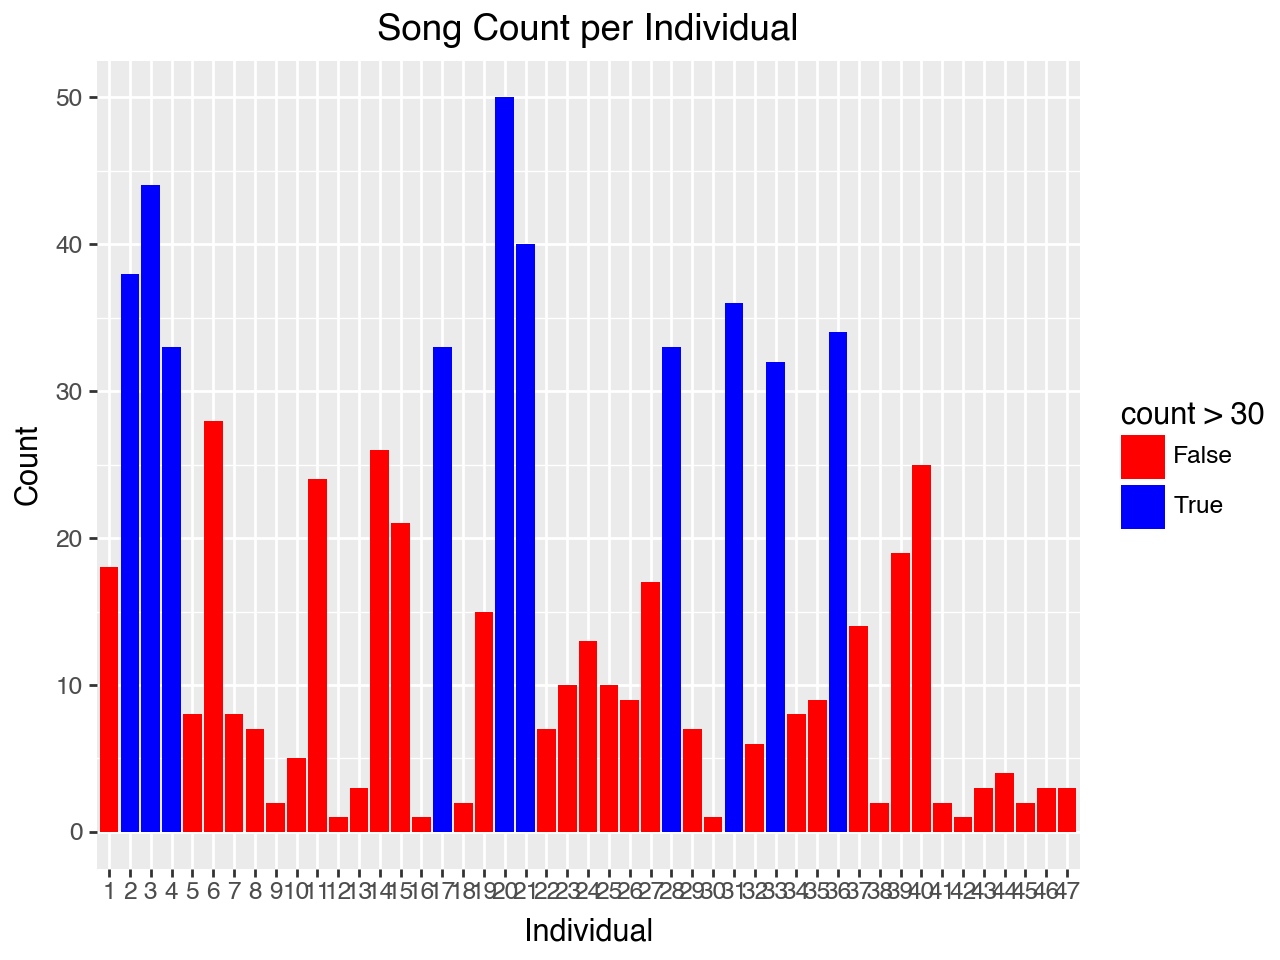

In [13]:
# Creates a ggplot object 
(
    ggplot(subst_loaded_events_df, aes(x='factor(individual)', fill='count > 30'))
    + geom_bar()
    + scale_fill_manual(
        values={True: 'blue', False: 'red'}
    )
    + labs(
        title='Song Count per Individual',
        x='Individual',
        y='Count'
    )
)

Now, we want to plot the recordings according to the relative (x, y) coordinates, they will be labeled according to the individual they belong to & faceted by the sites they belong to.

In [14]:
# Create the figure for this, using ast package to unpack the str
fig_df = pd.DataFrame()
fig_df['x'] = subst_loaded_events_df['relative_position'].apply(
    lambda p: ast.literal_eval(p)[0]
)
fig_df['y'] = subst_loaded_events_df['relative_position'].apply(
    lambda p: ast.literal_eval(p)[1]
)
fig_df['individual'] = subst_loaded_events_df['individual'].astype("category")

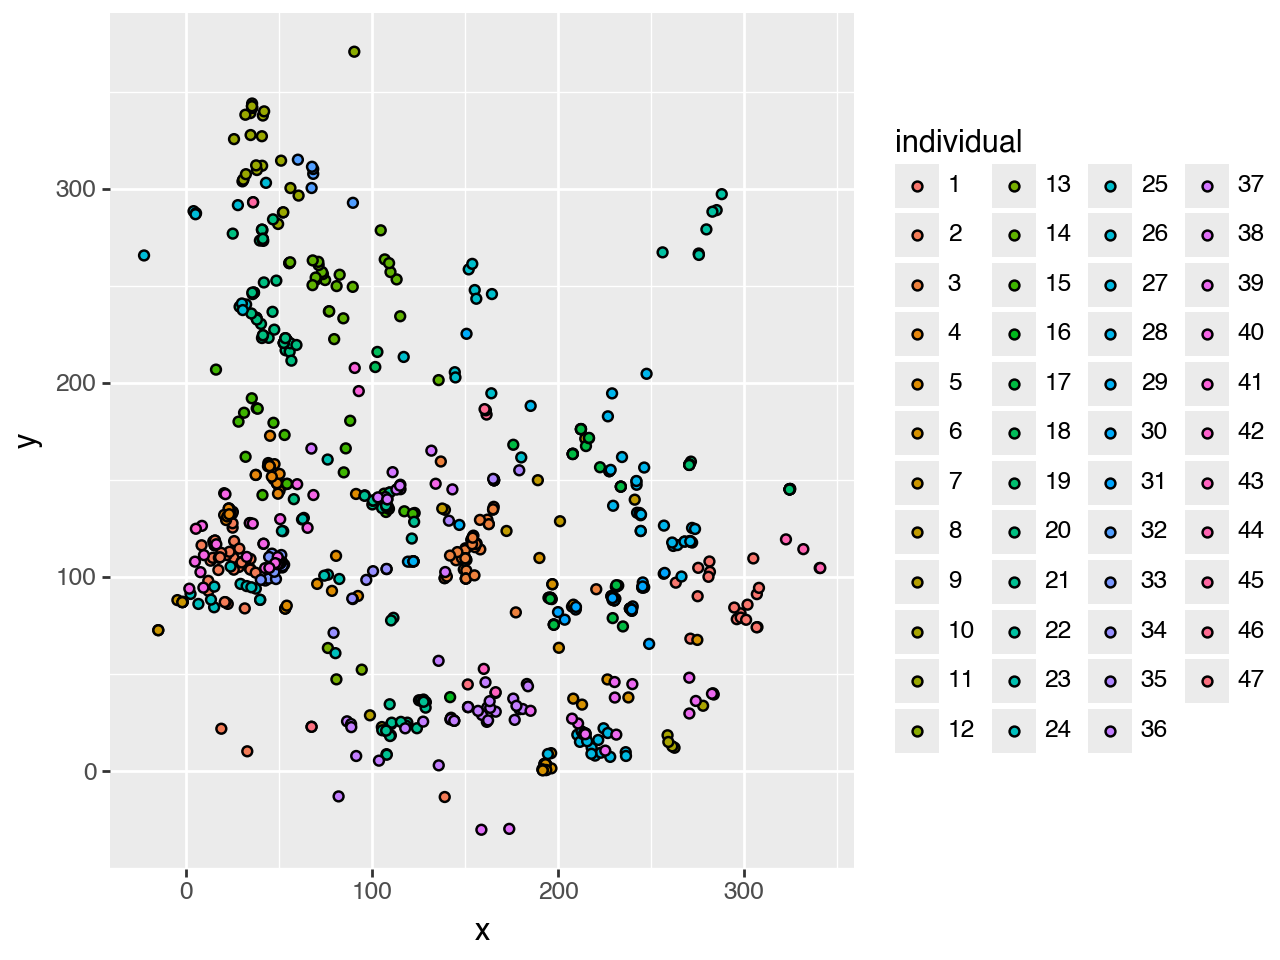

In [15]:
(
    ggplot(fig_df, aes('x', 'y', fill = 'individual')) +
        geom_point() 
)

Now, we will facet grid them by the site.

In [16]:
# Introduce the site column to enable facet gridding
fig_df['site'] = subst_loaded_events_df['array']

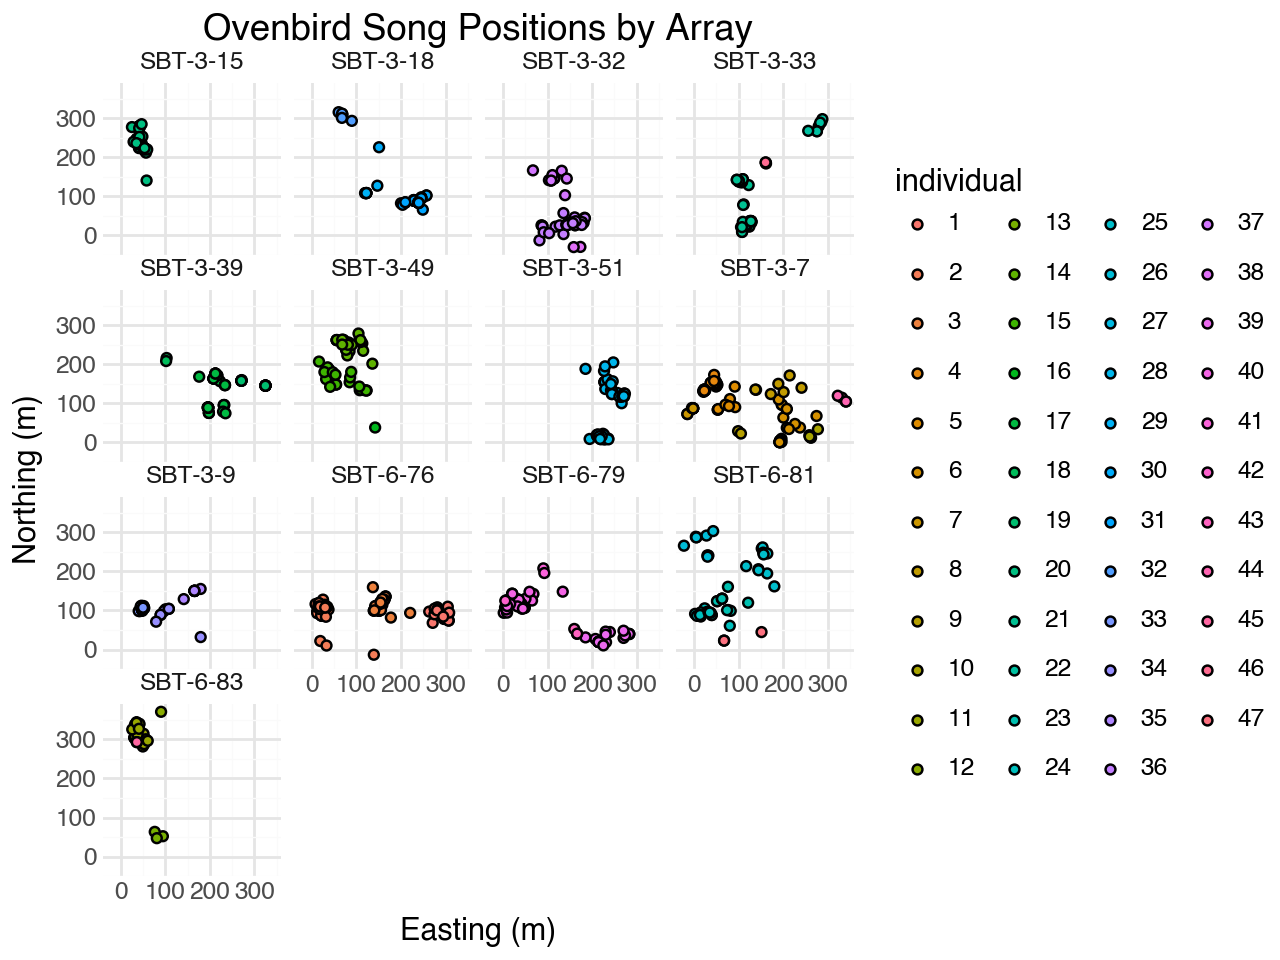

In [17]:
(
    ggplot(fig_df, aes('x', 'y', fill = 'individual')) +
        geom_point() +
        facet_wrap('site') +
        labs(
        title='Ovenbird Song Positions by Array',
        x='Easting (m)',
        y='Northing (m)',
        color='Individual'
        ) +
        theme_minimal()
)

## Acoustic Event Processing
The overlaps of all the bird recordings will be found, and that information will be used to determine bird interactions.
- If two bird recordings overlap, that may or may not be an interaction (further analysis is required)
- If two bird recordings do not overlap, that is not an interaction

### Data Preparation

Create a class to represent acoustic events, this will make it much easier in the future

In [18]:
class AcousticEvent:
    '''
    Class to represent the Acoustic Events from the data \n
    - Event Key \n
    - Individual Bird Identifer \n
    - Start Timestamp (Scaled) \n 
    - End Timestamp (Scaled) \n
    - X Coordinate (Meters) \n
    - Y Coordinate (Meters)
    '''
    def __init__(self, values: tuple) -> None:
        '''
        Initializes the AcousticEvent object to hold the attributes that will be used
        '''
        self.key, self.id, self.start, self.end, self.x, self.y, self.site = values

    def overlap(self, other: 'AcousticEvent'):
        '''
        Assumes the other AcousticEvent has a > than start timestamp
        '''
        return other.start < self.end

In [19]:
def create_acoustic_events(metrics_df: DataFrame) -> list[AcousticEvent]:
    '''
    Return a list of acoustic events from metrics_df
    '''
    event_tuples = list(metrics_df[['individual', 'scale_time_start', 'scale_time_end', 'position_x', 'position_y', 'site']].itertuples(index=True, name=None))
    acousticEvents = [AcousticEvent(tupleEvent) for tupleEvent in event_tuples]
    return acousticEvents

### Temporal Overlap Detection

In [20]:
def time_overlap(event_1: AcousticEvent, event_2: AcousticEvent) -> bool:
    '''
    Given two events: Event 1 and Event 2 (key, id, start, end, x, y), True if they overlap, false if not \n
    Invariant holds if the two events are presented in ascending sorted order \n
    O(1) time complexity, simply returns true or false
    '''
    return event_1.overlap(event_2)

In [21]:
# Find the overlap from all the events
def time_overlaps(events: list[AcousticEvent]) -> list[tuple[AcousticEvent]]:
    '''
    Finds a list of all event overlaps, then returns a list of them as tuples
    '''
    # We need to find all the ways the events overlap, then return a tuple of event ids 
    events_time_overlapped: list[tuple] = []
    events = sorted(events, key=lambda x: x.start) # key must use a function for comparison

    for i, event_1 in enumerate(events): 
        for event_2 in events[i+1:]: # compare to the rest after it
            if time_overlap(event_1, event_2): 
                events_time_overlapped.append((event_1, event_2)) 
            else:
                break
        
    return events_time_overlapped

Naively it works, but the overlap count appears to be very low. This suggests that the individual birds in the sites typically do not interrupt one another.

Now, we should specify upper and lower bounds to increase the overlaps. Eg. Two events overlap if they occurred within x minutes of one another.

### Testing Overlaps

At this point, we have sucessfully transformed those columns by adding and subtracting increments

In [22]:
# Parses the metrics dataframe rows into a list of tuples 
acoustic_events_scale = create_acoustic_events(metrics_df)

Now that we have successfully transformed the original dataframe to reflect a broader range, we will run the overlap algorithm on this.

In [23]:
event_time_overlapping_acoustic_events = time_overlaps(acoustic_events_scale) # We now have a list of all overlapping event ids

## Proximity Filtering

### Time Slider Setup

Set up the bottom and upper ranges for the user to offset by

In [24]:
# Minimum & Maximum range
min_dt_range = min(metrics_df['scale_time_start'])
max_dt_range = max(metrics_df['scale_time_end'])

In [25]:
#START = min_dt_range + pd.to_timedelta(START_OFF, unit="minute")
#END = START + pd.to_timedelta(DURATION, unit="minute")

START = min(metrics_df['scale_time_start'])
END = max(metrics_df['scale_time_end'])

In [26]:
range_time: tuple = (START, END)

In [27]:
### Time 
# Acoustic Event:(key, id, start, end, x, y, site)
# Time Range: (-1, -1, start, end, -1, -1, -1)
# Inputs: Distance_Range: int, events = (event_A, event_B)
def time_filter(time: tuple, events: list[AcousticEvent]) -> bool:
    """
    Returns if user specified time frame overlaps with the current one \n 
    Cannot rely on sort since time is not guaranteed to be before or events
    """
    start, end = time
    overlap_a = end > events[0].start and start < events[0].end
    overlap_b = end > events[1].start and start < events[1].end
    
    return overlap_a and overlap_b

### Distance Slider Setup

Allow the user to specify the distance that the birds have to be from each other to include in the graph visualization.

$D = \sqrt((Y_2 - Y_1)^2 + (X_2 - X_1)^2)$

In [28]:
# Distance: (X_2, Y_2) and (X_1, Y_1)
# Inputs: Distance_Range: int, events = (event_A, event_B)
def distance_filter(dist_range: int, events: list[AcousticEvent]):
    """
    Returns the Euclidean distance between two events A and B \n
    Does not rely on the sorting invariant
    """
    x1, y1 = events[0].x, events[0].y
    x2, y2 = events[1].x, events[1].y
    dist = math.sqrt((x2 - x1)**2 + (y2 - y1)**2)

    return dist <= dist_range

## Individual Identification
Using the unique event ids, we will find the corresponding individuals and plot only those events that occurred at the same time.

This function will be re-executed every time the user changes the time & proximity

In [29]:
def filter_events_individuals(acoustic_event_list: list[tuple], time: tuple, distance: int):
    '''
    Time - User Input \n
    Distance - User Input \n
    Filters the event list and returns a list of tuples of individuals that overlap. \n
    If time is True, then overlap by that prior \n 
    '''
    individuals = [] # (individual_1, individual_2)
    for (event_a, event_b) in acoustic_event_list:
        
        t_filter = time_filter(time = time, events = [event_a, event_b])
        d_filter = distance_filter(dist_range = distance, events = [event_a, event_b])
        
        conds = event_a.site != event_b.site or event_a.id == event_b.id or not t_filter or not d_filter
        
        if conds: continue
        else: individuals.append((event_a, event_b))

    return individuals

### Individual Filtering Setup
Now that the filtering algorithm is complete, we will run it on the data set to find individuals

In [30]:
individuals = filter_events_individuals(acoustic_event_list=event_time_overlapping_acoustic_events, time=range_time, distance=EUCLIDEAN_DIST)

## Bird Network Construction

Now we have a list of the individuals with overlapping acoustic records, we have enough information to create visualization of the graphs.

Import the networkX library in order to store the individuals into the graph.

This function will be re-executed when the user changes the time and proximity sliders

### Bird Network Edge

In [ ]:
class BirdNetworkEdge:
    '''
    A class to represent an edge within the bird network \n
    It weighted according to the sum of Temporal & Spacial Proximity and the Historical Frequency \n
    In weeks 6/7, we can begin adding weights that the Machine Learning for learning \n
    self.raw_weight = self.TemporalProximity + self.SpacialProximity \n
    self.HistorialFrequency = 0 \n
    Testing currently...
    '''
    def __init__(self, event_A: AcousticEvent, event_B: AcousticEvent) -> None:
        """
        Given two acoustic events, initialize the Temporal & Spacial Proximity
        """
        # In minutes
        self.upper_range_raw_temporal = 10
        self.maximum_proximity_temporal = 100

        # In meters 
        self.upper_range_raw_spatial = 50
        self.maximum_proximity_spatial = 100

        self.TemporalProximity = self.calculate_temporal_proximity(event_A=event_A, event_B=event_B)
        self.SpacialProximity = self.calculate_spacial_proximity(event_A=event_A, event_B=event_B)
    
    def calculate_temporal_proximity(self, event_A: AcousticEvent, event_B: AcousticEvent) -> int:
        """
        Given two acoustic events, calculate the temporal proximity according to the following formulation \n
        Event A: (start_A, end_A) and Event B: (start_B, end_B) \n
        Example: start_A > end_B: D = start_A - end_B \n
        - As D -> 0, T -> X: Bird A vocalizes after Bird B's vocalization instantly, increases chances of an interaction
        - As D -> R: Bird A vocalizes a fixed time R after Bird B's vocalization, reduced chances of an interaction
        - As R <= D -> inf: Bird A vocalizes a long time after Bird B's vocalization, chances of an interaction approach 0
        """

        return 0

    def calculate_spacial_proximity(self, event_A: AcousticEvent, event_B: AcousticEvent) -> float:
        """
        Given two acoustic events, calculate the spacial proximity according to the following formulation \n
        Event A: (pos_x_A, pos_y_A) and Event B: (pos_x_B, pos_y_B) \n
        Example: start_A > end_B: D = \\sqrt[ ( pos_y_B - pos_y_A )**2 + ( post_x_B - pos_y_A )**2 ]\n 
        - As D -> 0, T -> X: Bird A's vocalization is very close to Bird B's vocalization, increases chances of an interaction to Upper Range
        - As D -> R: Bird A vocalization approaches the fixed distance R from Bird B's vocalization, reduced chances of an interaction to Lower Range
        - As R <= D -> inf: Bird A's vocalization is far from Bird B's vocalization, chances of an interaction approach 0
        """
        dist = math.sqrt((event_B.x - event_A.x)**2 + (event_B.y - event_A.y)**2)
        # Any distance that is less than the upper range follows the formula, anything greater recieves a value of 0
        if dist > self.upper_range:
            return 0
        elif dist == self.upper_range:
            return self.lower
        return 1 - (dist / self.upper)

### Static Undirected Bird Network

In [ ]:
# Now we can iterate over the list of tuples, adding them to the Graph
# ({name, info}, {name, info}) : These two individual birds had an event overlap, each with its own metadata
# This function will be reran with different user configurations for every change
def create_static_undirected_bird_network(individuals_list: list[tuple[AcousticEvent]]) -> nx.Graph:
    """
    Using the list of individual overlaps, create an undirected static bird network \n
    Computed for each user configuration
    """
    bird_net = nx.Graph()
    for overlap_a, overlap_b in individuals_list: # type: ignore
        bird_net.add_node(overlap_a.id)
        bird_net.add_node(overlap_b.id)

        if bird_net.has_edge(overlap_a.id, overlap_b.id):
            bird_net[overlap_a.id][overlap_b.id]["weight"] += 1  # increment on repeat overlap
        else:
            bird_net.add_edge(overlap_a.id, overlap_b.id, weight=1)  
    return bird_net

### Dynamic Directed Bird Network

In [ ]:
def create_dynamic_directed_bird_network():
    """
    Using the list of individual overlaps, create a directed dynamic bird network \n
    Computed for each user configuration
    """
    pass

## Network Visualization

### Static Network Visualization

The chunks following provide a static snapshot of the state of the network for a given time window and distance.

In [ ]:
bird_net = create_static_undirected_bird_network(individuals)

In [ ]:
components = list(nx.connected_components(bird_net))
cmap = plt.get_cmap("tab20") # 20 distinct colors

In [ ]:
# Build a site -> color mapping
site_map = {}  # node -> site
for node in bird_net.nodes(): 
    site_map[node] = subst_loaded_events_df[
        subst_loaded_events_df["individual"] == node
    ].iloc[0]["array"]

sites = list(set(site_map.values())) # names of the arrays
indices = [0, 2, 4, 6, 8, 10, 12, 14, 16, 18, 1]  # 11 distinct indices from tab20
site_colors = {site: cmap(indices[i]) for i, site in enumerate(sites)} # maps each site to color

In [ ]:
net = Network(notebook=True, height="750px", width="100%")

# Add nodes
for i, component in enumerate(components): # Color changes based on components
    for node in component: # Will be the same color
        site = site_map[node]
        color = site_colors[site] # fetch the color for each component
        hex_color = "#{:02x}{:02x}{:02x}".format(
            int(color[0]*255), int(color[1]*255), int(color[2]*255)
        )
        net.add_node(node,
                     label=str(node),
                     color=hex_color,
                     font={"size": 14, "color": "black", "align": "center"})

# Add edges with normalized weights
weights = [data.get("weight", 1) for _, _, data in bird_net.edges(data=True)]
min_w, max_w = min(weights), max(weights)

for src, dest, data in bird_net.edges(data=True):
    w = data.get("weight", 1)
    normalized = 1 + 14 * (w - min_w) / (max_w - min_w)
    net.add_edge(src, dest, value=normalized)

# Toggle the buttons and show the canvas
net.show_buttons(filter_=["physics"])
net.show("bird_net.html")

### Dynamic Network Visualization

## Extended Data Set
Prior, we worked with the small Localization data set to gain familiarity. In the following section, we will extend these methods to the larger unannotated data set.

The goal is to create a network from the much larger data set and examine how well the methodology used above generalizes to this. The Snowy HPC at the Kitzes Lab will be the primary medium that will be used to execute the following scripts.

## [TODO] Mathematical Modeling

In order to capture the interactions as precisely as possible, a mathematical model comprising the spatial & temporal aspects of the data will be formulated.

Here are the symbols that will be utilized for this formulations:
- $I$ denotes the interaction between two individual birds
- $I, J$ denote the observed acoustic events of two distinct individual birds
- $\beta_i \in \{\beta_0, \beta_1, \ldots \}$ denote the weights that should be applied
- $S(i, j)$ denotes the Euclidean Distance between i and j in meters, normalized to [0, 1] in which 1 is the closest
- $T(i, j)$ denotes the Temporal Proximity between i and j in minutes, normalized to [0, 1] in which 1 meaning no delay
- $H(i, j)$ denotes the number of historical interactions between i and j, normalized to [0, 1]
- $\theta_{ij} = \beta_0 + \beta_1 \times S(i, j) + \beta_2 \times T(i, j) + \beta_3 \times H(i, j)$ 
- $\sigma = \frac{1}{1 + e^{-\theta_{ij}}}$ denotes the logistic sigmoid function that maps into the range [0, 1]

### Edge Weights

$P(I \mid X, Y) = \sigma [\beta_0 + \beta_1 \times S(X, Y) + \beta_2 \times T(X, Y) + \beta_3 \times H(X, Y)] = \sigma [\theta_{ij}] = z$

In other words, the probability of an interaction occurring given evidence for X and Y is the logistic transformation of the linear combination of the Spatial Temporal Evidence. 

$\beta$ coefficients are free parameters that will be estimated from the data via Bayesian Inference

$P(I \mid X, Y) \propto P(X, Y \mid I) \times P(I)$

The above is the Bayesian formulation for the same phenomena. The probability that an interaction has occurred given evidence from two birds is equivalent to the probability of the evidence given the interaction times the probability of the interaction occurring. The evidence term refers to all the interactions between X & Y, which is left out as it is expensive to calculate in addition to being nearly intractable.

### Future Additions
Identify the angle at which a chirp is coming from the further increase the accuracy of the model. 